# Лабораторная работа № 1.2
---
«Исследование данных»

Рязанцев Георгий Борисович

In [ ]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

df = pd.read_csv('Customers.csv', sep=";", decimal=",") 
df[['Prices', 'Number', 'Customer_id']] = df[['Prices', 'Number', 'Customer_id']].astype(float) 

In [5]:
df = df[(df['Prices'] < 5500) & (df['Prices'] > 00)] 

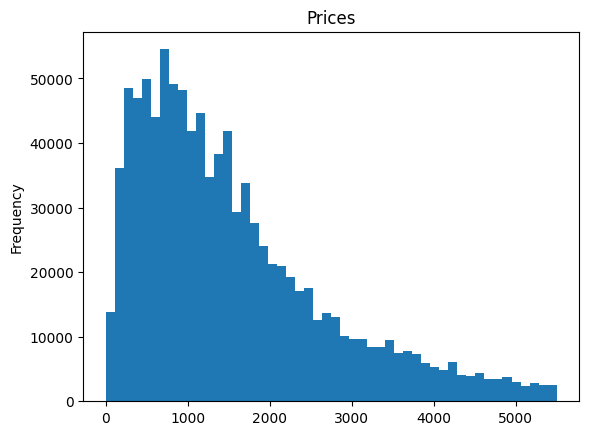

In [6]:
df['Prices'].plot(kind='hist', bins=50, title='Prices')
plt.show()

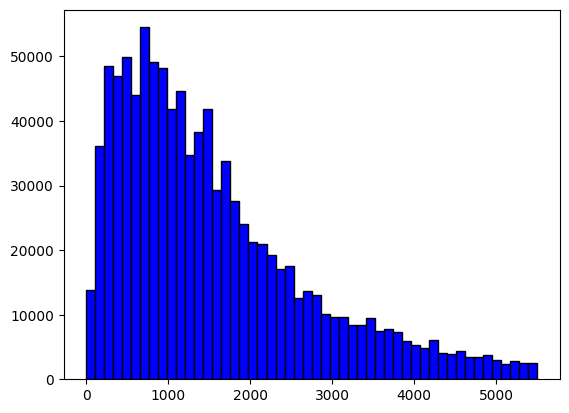

In [7]:
plt.hist(df['Prices'], color = 'blue', edgecolor = 'black', bins = 50)
plt.show()

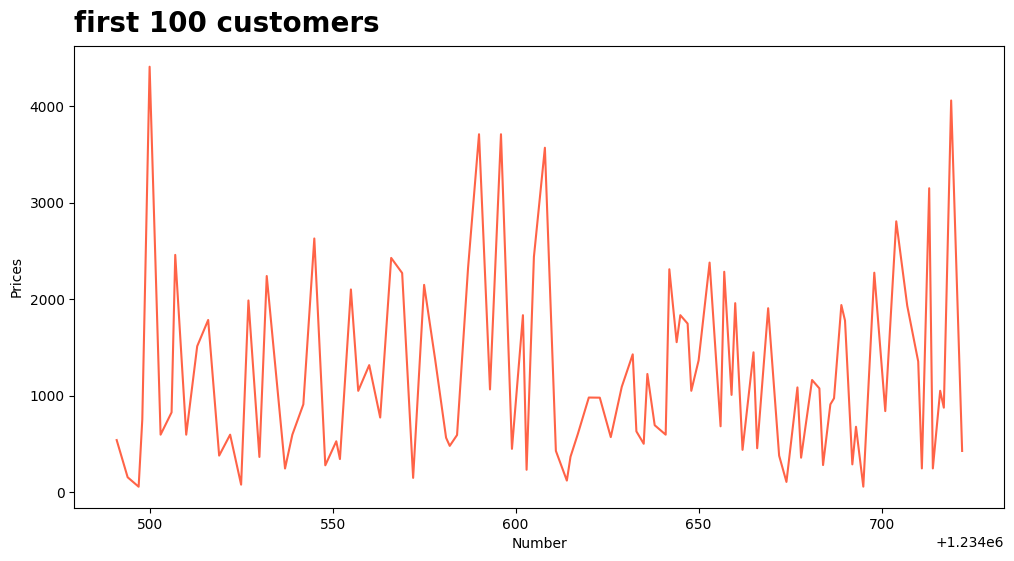

In [8]:
df1 = df[:100]
import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
plt.plot(df1["Number"], df1["Prices"], color="tomato")

plt.xlabel("Number")
plt.ylabel("Prices")
plt.yticks()

plt.title("first 100 customers", loc="left",
fontdict=dict(fontsize=20, fontweight="bold"), pad=10)
plt.show() 

In [9]:
df = pd.read_csv('Customers.csv', sep=";", decimal=",") 
df[['Prices', 'Number', 'Customer_id']] = df[['Prices', 'Number', 'Customer_id']].astype(float)
print(df.head())

      Number  Customer_id  Prices        Date
0  1234491.0     337544.0   539.0  01.01.2018
1  1234494.0     171642.0   153.3  01.01.2018
2  1234497.0     260596.0    55.3  01.01.2018
3  1234498.0    1105609.0   752.5  01.01.2018
4  1234500.0     982696.0  4410.0  01.01.2018


In [ ]:
df["DateTime"] = pd.to_datetime(df["Date"], format="%d.%m.%Y", errors="coerce") 

df = df.dropna(subset=['DateTime'])
df = df.sort_values('DateTime')

dfgrouped = df.groupby('DateTime', as_index=False)['Prices'].sum().copy()
print(dfgrouped)

      DateTime     Prices
0   2018-01-01  1157712.5
1   2018-01-02  1829328.2
2   2018-01-03  2386240.5
3   2018-01-04  2510487.0
4   2018-01-05  2779490.7
..         ...        ...
432 2019-03-09  7603146.5
433 2019-03-10  6759764.4
434 2019-03-11  5958958.5
435 2019-03-12  5717748.1
436 2019-03-13  6406937.1

[437 rows x 2 columns]


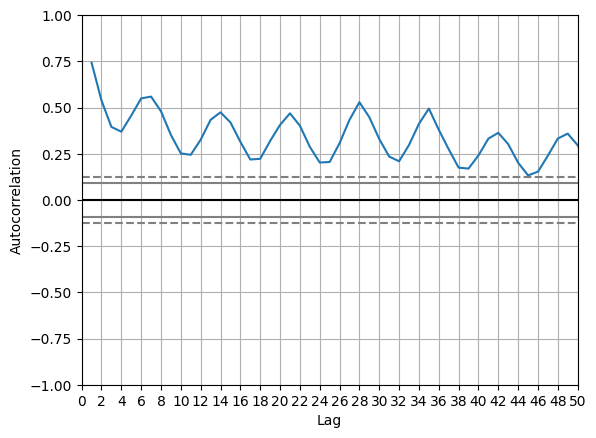

In [ ]:
from pandas.plotting import autocorrelation_plot
import matplotlib.pyplot as plt

ax = autocorrelation_plot(dfgrouped['Prices'])

left = 0
right = 50

ax.set_xlim(left, right)

ax.set_xticks(range(left, right + 1,right//20))
plt.show()

In [12]:
from pandas import DataFrame
from pandas import concat

shval = 1
values = DataFrame(dfgrouped["Prices"].values)
dataframe = concat([values.shift(shval), values], axis=1)
dataframe.columns = ['t-' + str(shval), 't']
result = dataframe.corr()
print(result)

          t-1         t
t-1  1.000000  0.744739
t    0.744739  1.000000


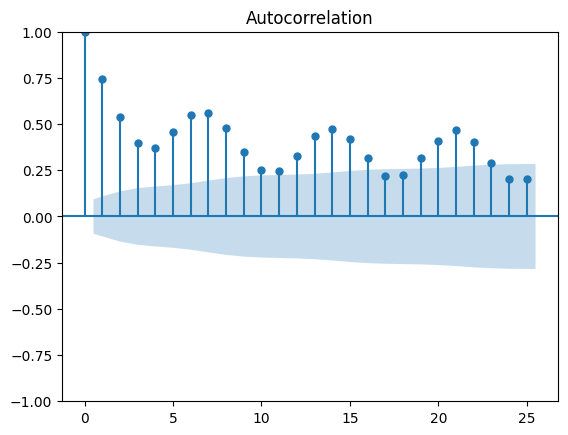

In [13]:
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(dfgrouped["Prices"], lags=25)
plt.show() 

### Вопросы для самоконтроля
---
1. *В чем заключается этап «Исследование данных»?*

— Построение графиков, выявление закономерностей, трендовая, сезонная компонента

2. *Какие возможности по исследованию данных предоставляет среда
Google Colab?*

— Ряд графиков для некоторых показателей датасета

3. *Какие выводы могут быть получены при построении гистограммы,
линейного графика и автокорреляционной функции?*

— Наличие зависимостей между данными

4. *Какой метод Python применяется для построения матрицы
автокорреляции?*

— corr() и shift()

5. *Какие Python библиотеки были использованы на этапе «Исследование
данных»?* 

— pandas, matplotlib, seaborn, numpy, statsmodels

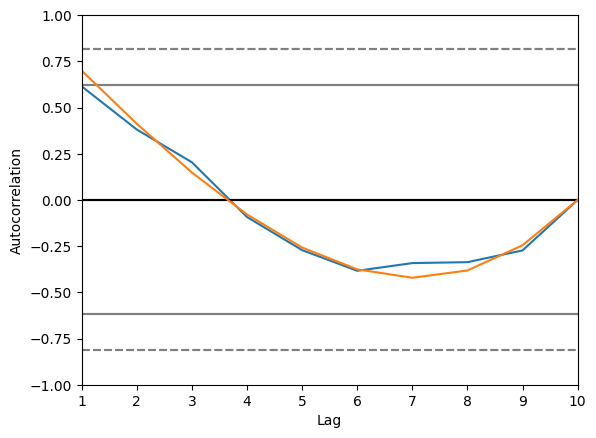

In [27]:
autocorrelation_plot([1, 2, 3, 4, 5, 6, 8, 7, 7.5, 10])
autocorrelation_plot([10, 9, 8, 7, 6, 5, 4, 3, 2, 1]) #identical to the first one
plt.show()

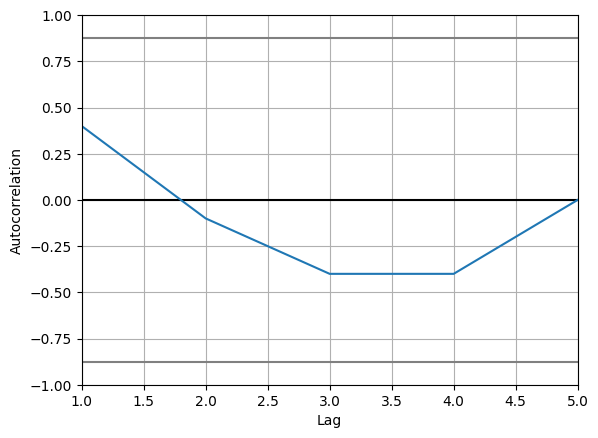

In [21]:
autocorrelation_plot([5, 4, 3, 2, 1]) #identical to the first one
plt.show()